# 03 - Exploratory Data Analysis (EDA)

## Objective

The main objectives are to:

- Understand the statistical properties of the data.
- Analyze individual attribute distributions.
- Investigate relationships between attributes.
- Identify correlations and potential redundancy.
- Explore differences between Information Operations
  (IO) and control accounts.
- Identify useful features for account-level profiling
  and subsequent clustering.

In [68]:

# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [69]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/Users/ramy/Courses/Data Mining /project/Data-Mining-Project-"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "data_processed"
    / "df_clean_final.csv.gz"
)

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.is_file())

assert DATA_PATH.is_file(), "Cleaned dataset not found."

Dataset path: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-/data/data_processed/df_clean_final.csv.gz
Dataset exists: True


In [70]:

# ============================================================
# 3. DATASET PREVIEW AND STRUCTURE
# ============================================================

print("=== CLEANED DATASET PREVIEW ===")

# Read only five rows to avoid unnecessary memory usage
df_preview = pd.read_csv(
    DATA_PATH,
    nrows=5,
    dtype="string",
    compression="gzip"
)

display(df_preview)

# Verify expected dataset structure
total_columns = df_preview.shape[1]

print(f"\nTotal attributes: {total_columns}")

print("\n=== ATTRIBUTE NAMES ===")

for index, column in enumerate(df_preview.columns, start=1):
    print(f"{index:02d}. {column}")

assert total_columns == 20, (
    "Unexpected number of attributes in cleaned dataset."
)

print("\nDataset preview completed successfully.")


=== CLEANED DATASET PREVIEW ===


,ioCountry,postid,post_text,application_name,post_language,in_reply_to_postid,in_reply_to_accountid,post_time,accountid,account_profile_description,follower_count,following_count,account_creation_date,is_repost,reposted_accountid,reposted_postid,hashtags,urls,account_mentions,is_control
0,ecuador,0bafe020a260495bee38b98fde83668d924454019b,Vamos a cambiar la forma de hacer comunicación...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 02:52:00+00:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528.0,2619.0,2010-03-11 00:00:00+00:00,False,<NA>,<NA>,[],[],[],False
1,ecuador,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,"Damos servicio de manejo de prensa, elaboració...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 03:08:00+00:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528.0,2619.0,2010-03-11 00:00:00+00:00,False,<NA>,<NA>,[],[],[],False
2,ecuador,514b2c38b26e240cac85382be74ed7d61a02468ac1,@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,2010-03-13 15:26:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28 00:00:00+00:00,False,<NA>,<NA>,[],[],['db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302'],False
3,ecuador,e82a816068e88387d19430348f0420b040e0d11b4e,"Mario, debemos denuciar que en los poderes pub...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 15:32:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28 00:00:00+00:00,False,<NA>,<NA>,[],[],[],False
4,ecuador,13ed6aaeec4fffaf840f1c42ff88f5ab2cb324be64,Tambien debemos estar claro que la oposición e...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 15:35:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28 00:00:00+00:00,False,<NA>,<NA>,[],[],[],False



Total attributes: 20

=== ATTRIBUTE NAMES ===
01. ioCountry
02. postid
03. post_text
04. application_name
05. post_language
06. in_reply_to_postid
07. in_reply_to_accountid
08. post_time
09. accountid
10. account_profile_description
11. follower_count
12. following_count
13. account_creation_date
14. is_repost
15. reposted_accountid
16. reposted_postid
17. hashtags
18. urls
19. account_mentions
20. is_control

Dataset preview completed successfully.



### A.1 Identification of Ambiguous Post Ownership

**Objective:** Identify posts associated with conflicting account identifiers before account-level analysis.

**Background:** Part 2 identified 296 conflicting `(ioCountry, postid)` groups, including 226 groups where the same post was associated with different account IDs.

**Methodology:**

1. Load the conflict report generated during data-quality assessment.
2. Identify groups marked with `accountid_conflict = True`.
3. Extract unique `(ioCountry, postid)` combinations representing ambiguous post ownership.
4. Prepare these identifiers for filtering during account-level aggregation.

**Decision:** Retain all accounts and preserve the original cleaned dataset. Exclude ambiguous post ownership records only from analyses where reliable attribution is required.

**Purpose:** Prevent uncertain ownership from distorting account-level behavioral features and subsequent clustering.

**Expected outcome:** A validated reference set of ambiguous post identifiers.


In [71]:

# ============================================================
# A.1 IDENTIFICATION OF AMBIGUOUS POST OWNERSHIP
# ============================================================

# Locate the conflict report exported from Part 2
CONFLICT_PATH = DATA_PATH.parent / "conflicting_records.csv"

print("=== AMBIGUOUS POST OWNERSHIP ===")
print("Conflict report:", CONFLICT_PATH)
print("File exists:", CONFLICT_PATH.is_file())

assert CONFLICT_PATH.is_file(), (
    "Conflict report not found. "
    "Check the export from Part 2, Section 2.6."
)

# Load the small conflict report only
conflict_records = pd.read_csv(
    CONFLICT_PATH,
    dtype={
        "ioCountry": "string",
        "postid": "string",
        "accountid": "string"
    }
)

# Verify required columns
required_columns = {
    "ioCountry",
    "postid",
    "accountid",
    "accountid_conflict"
}

assert required_columns.issubset(conflict_records.columns), (
    "Required columns are missing from the conflict report."
)

# Identify ownership conflicts
ownership_mask = (
    conflict_records["accountid_conflict"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("true")
    .fillna(False)
)

ownership_conflicts = conflict_records.loc[
    ownership_mask
].copy()

# One unique key per ambiguous post
ambiguous_post_keys = (
    ownership_conflicts[["ioCountry", "postid"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Reference index used later during chunk processing
ambiguous_post_index = pd.MultiIndex.from_frame(
    ambiguous_post_keys
)

# Summary
total_conflicting_groups = (
    conflict_records[["ioCountry", "postid"]]
    .drop_duplicates()
    .shape[0]
)

print("\n=== CONFLICT SUMMARY ===")
print(f"Total conflicting groups: {total_conflicting_groups:,}")
print(f"Ambiguous ownership groups: {len(ambiguous_post_keys):,}")
print(f"Affected records: {len(ownership_conflicts):,}")

# Validate expected findings
assert total_conflicting_groups == 296
assert len(ambiguous_post_keys) == 226

print("\nOwnership conflict identification completed.")
print("The cleaned dataset has not been modified.")


=== AMBIGUOUS POST OWNERSHIP ===
Conflict report: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-/data/data_processed/conflicting_records.csv
File exists: True

=== CONFLICT SUMMARY ===
Total conflicting groups: 296
Ambiguous ownership groups: 226
Affected records: 460

Ownership conflict identification completed.
The cleaned dataset has not been modified.



### A.2 Filtering Ambiguous Ownership Records

**Objective:** Prepare a consistent filtering method for account-level exploratory analysis.

**Methodology:**

1. Match each record against the ambiguous `(ioCountry, postid)` keys identified in Section A.1.
2. Separate records with reliable ownership from records with ambiguous ownership.
3. Preserve all original records in the cleaned dataset.
4. Use the reliable records for post-based account statistics.
5. Track ambiguous records separately for auditing.

**Decision:** Exclude ambiguous ownership records only from aggregations that require reliable post-to-account attribution. Do not arbitrarily assign them to an account.

**Memory efficiency:** Apply the filtering function to individual data chunks rather than loading the complete dataset.

**Expected outcome:** A reusable function for safe account-level aggregation.


In [72]:

# ============================================================
# A.2 FILTER AMBIGUOUS OWNERSHIP RECORDS
# ============================================================

def split_by_ownership(chunk):
    """
    Separate records with reliable and ambiguous post ownership.

    Returns:
        reliable_records: Records eligible for account aggregation.
        ambiguous_records: Records excluded from aggregation.
    """

    # Use the same identifier representation as Section A.1
    keys = chunk[["ioCountry", "postid"]].astype("string")

    chunk_index = pd.MultiIndex.from_frame(keys)

    # Identify ambiguous ownership
    ambiguous_mask = chunk_index.isin(ambiguous_post_index)

    # Separate records without modifying the original chunk
    reliable_records = chunk.loc[~ambiguous_mask].copy()
    ambiguous_records = chunk.loc[ambiguous_mask].copy()

    return reliable_records, ambiguous_records


# Test the function using the small conflict report
test_reliable, test_ambiguous = split_by_ownership(
    conflict_records
)

print("=== OWNERSHIP FILTER TEST ===")
print(f"Input records: {len(conflict_records):,}")
print(f"Reliable ownership records: {len(test_reliable):,}")
print(f"Ambiguous ownership records: {len(test_ambiguous):,}")

# Verify all records are accounted for
assert (
    len(test_reliable) + len(test_ambiguous)
    == len(conflict_records)
)

assert len(test_ambiguous) == 460

print("\nOwnership filtering function validated.")
print("Original dataset remains unchanged.")


=== OWNERSHIP FILTER TEST ===
Input records: 601
Reliable ownership records: 141
Ambiguous ownership records: 460

Ownership filtering function validated.
Original dataset remains unchanged.


## B. Descriptive Statistics

This section investigates the statistical characteristics
of the cleaned dataset, including central tendency,
dispersion, and variability.

The objective is to better understand the data and
identify potentially informative features for
account-level profiling and clustering.

we will start with the follower and following counts, it will be done at the accounts level, first lets check how many accounts do we have

In [73]:
CHUNK_SIZE = 200_000

columns = [
    "ioCountry",
    "accountid",
    "postid",
    "post_time",
    "follower_count",
    "following_count"
]

account_keys = ["ioCountry", "accountid"]

df_accounts = pd.DataFrame()



for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype={"accountid": "string", "ioCountry": "string"},
    chunksize=CHUNK_SIZE
):
    # Exclude posts with ambiguous account ownership
    chunk, _ = split_by_ownership(chunk)

    # Convert post_time to datetime
    chunk["post_time"] = pd.to_datetime(
        chunk["post_time"],
        errors="coerce",
        utc=True
    )

    # Keep the rest of your existing code here


    chunk = chunk.dropna(
        subset=account_keys + ["post_time"]
    )

    # Keep the most recent record of each account
    chunk = (
        chunk.sort_values("post_time", kind="stable")
        .drop_duplicates(subset=account_keys, keep="last")
    )

    # Combine with previously processed accounts
    df_accounts = pd.concat(
        [df_accounts, chunk],
        ignore_index=True
    )

    df_accounts = (
        df_accounts.sort_values("post_time", kind="stable")
        .drop_duplicates(subset=account_keys, keep="last")
    )

df_accounts = df_accounts.reset_index(drop=True)

print(f"Number of accounts: {len(df_accounts):,}")

display(df_accounts.head())

Number of accounts: 86,524


,ioCountry,postid,post_time,accountid,follower_count,following_count
0,russia_1,3bfcf4dbfbd087c63c9cb3ed1073e7e28746d1901f,2009-11-22 23:59:26+00:00,c5bf20b8b883fd0c5689c64bee8ae7bd81d97698f6,125.0,0.0
1,russia_1,3289cf0e8adb46bb887c6177838374f0ddc23f88a7,2009-11-23 23:59:58+00:00,be64bf6b9b53f31e552be1bcaa0299143a51797dce,3248.0,2473.0
2,russia_1,cfce275da57bf3a0c3fef21a508470de31d451ba09,2009-11-23 23:59:58+00:00,703a8bb61d6ddb7168f50bebc3a753d88ba09a2d98,33.0,22.0
3,russia_1,316dbfe4d91645c5c4deab23ed7a176cfa1f962e8b,2009-11-24 23:59:58+00:00,2e1e7459112a2f14ce968cbc6e967725426962cb85,469.0,537.0
4,russia_1,93d074140a85c65b35ed22980ba620711cfdb9a4d7,2009-11-24 23:59:58+00:00,ae36bdb6544c22720f180f2b079218b50b7d3a098e,68.0,167.0


In [74]:
numerical_attributes = [
    "follower_count",
    "following_count"
]

display(
    df_accounts[numerical_attributes]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
follower_count,86520.0,10163.203779,185854.641640,0.0,97.0,385.0,1433.0,13815.0,101521.06,19912528.0
following_count,86521.0,1811.933854,12883.603022,0.0,118.0,406.0,1235.0,5001.0,21654.40,2301841.0


Visualisation:
- Each histogram contains 50 bins, where each bin represents
  an interval of follower or following counts
- The height of each bin represents the number of accounts
within that interval.

We used only the 95th percentile because including extremely large values would stretch the X-axis and make the distribution of most accounts difficult to observe.


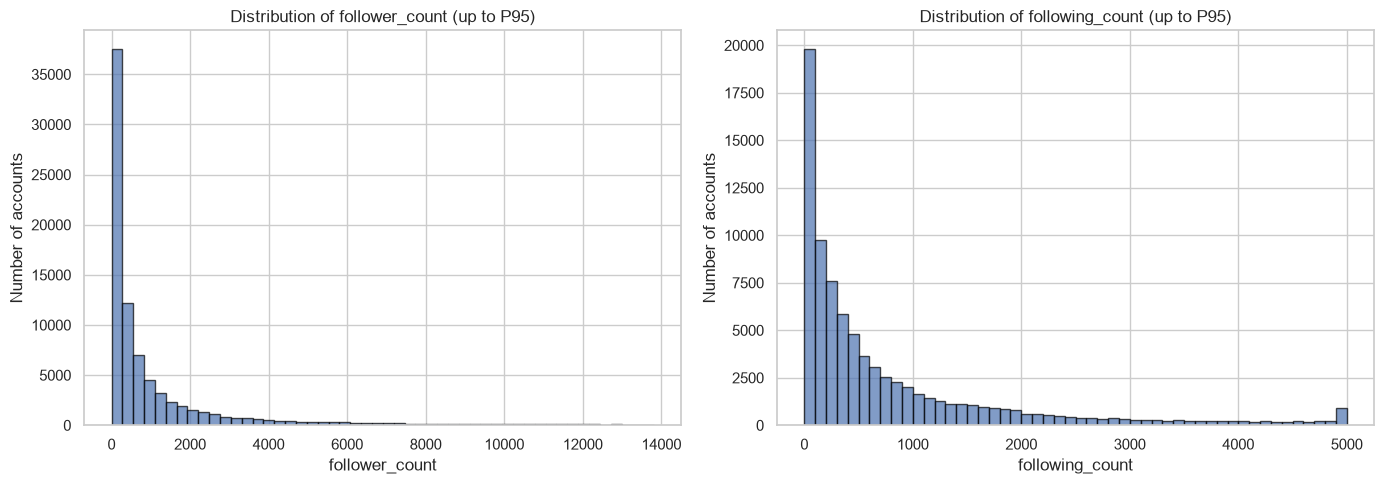

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["follower_count", "following_count"]):

    values = df_accounts[column].dropna()
    upper_limit = values.quantile(0.95)

    ax.hist(
        values[values <= upper_limit],
        bins=50,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column} (up to P95)")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

Now we will move to Account Age and Activity Lifespan.

These attributes could be particularly useful for understanding behavioral differences between IO and control accounts.
Because IO accounts may be created and operated for specific information campaigns, while control accounts may be used for ordinary, long-term social media activity.

In [76]:
columns = [
    "ioCountry",
    "accountid",
    "account_creation_date",
    "post_time"
]

df_temporal = pd.DataFrame()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype={"accountid": "string", "ioCountry": "string"},
    chunksize=CHUNK_SIZE
):
    chunk["post_time"] = pd.to_datetime(
        chunk["post_time"], errors="coerce", utc=True
    )

    chunk["account_creation_date"] = pd.to_datetime(
        chunk["account_creation_date"], errors="coerce", utc=True
    )

    chunk = chunk.groupby(account_keys).agg(
        creation_date=("account_creation_date", "min"),
        first_post=("post_time", "min"),
        last_post=("post_time", "max")
    ).reset_index()

    df_temporal = pd.concat(
        [df_temporal, chunk], ignore_index=True
    )

    df_temporal = df_temporal.groupby(account_keys).agg(
        creation_date=("creation_date", "min"),
        first_post=("first_post", "min"),
        last_post=("last_post", "max")
    ).reset_index()

In [77]:
df_temporal["account_age_days"] = (
    df_temporal["last_post"].dt.normalize()
    - df_temporal["creation_date"].dt.normalize()
).dt.days

df_temporal["activity_lifespan_days"] = (
    df_temporal["last_post"].dt.normalize()
    - df_temporal["first_post"].dt.normalize()
).dt.days

display(
    df_temporal[[
        "account_age_days",
        "activity_lifespan_days"
    ]].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
account_age_days,86525.0,993.341000,887.809747,0.0,243.0,750.0,1509.0,2815.0,3353.0,4493.0
activity_lifespan_days,86525.0,40.498943,163.007385,0.0,0.0,0.0,0.0,255.0,889.0,3288.0


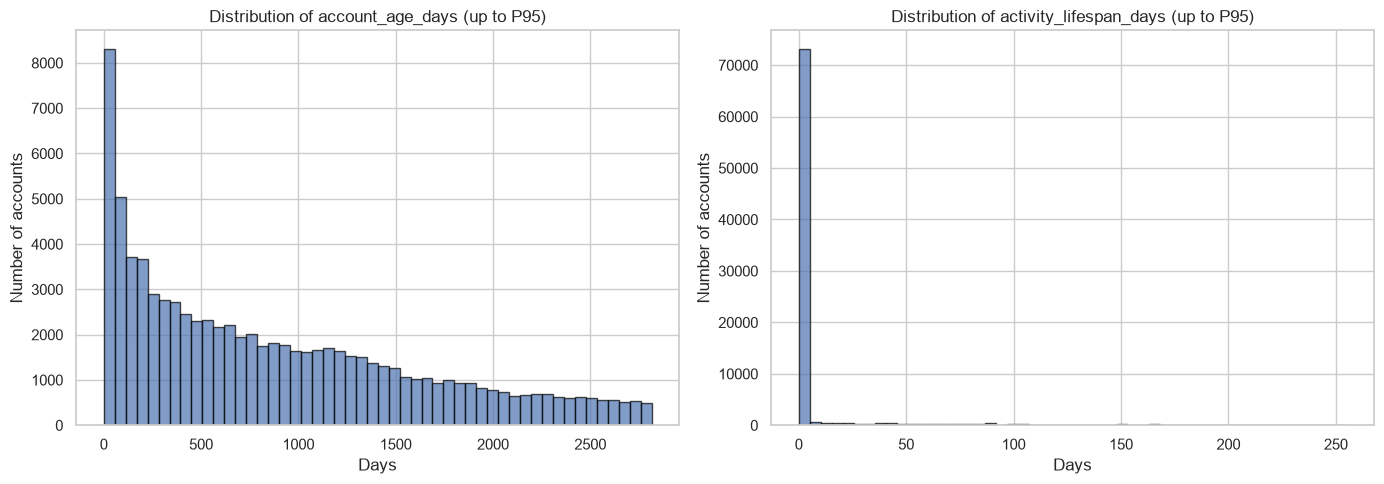

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(
    axes, ["account_age_days", "activity_lifespan_days"]
):
    values = df_temporal[column].dropna()
    upper_limit = values.quantile(0.95)

    ax.hist(
        values[values <= upper_limit],
        bins=50,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column} (up to P95)")
    ax.set_xlabel("Days")
    ax.set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

### B.3 Number of Posts per Account

We calculate the total number of observed posts for each
account

In [79]:

from collections import Counter

post_counts = Counter()
ambiguous_counts = Counter()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=account_keys + ["postid"],
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Separate reliable and ambiguous ownership
    reliable_chunk, ambiguous_chunk = split_by_ownership(chunk)

    # Count only reliable posts for behavioral analysis
    counts = reliable_chunk.groupby(account_keys).size()
    post_counts.update(counts.to_dict())

    # Track excluded records for each account
    conflicts = ambiguous_chunk.groupby(account_keys).size()
    ambiguous_counts.update(conflicts.to_dict())

# Keep every account encountered in either group
all_accounts = post_counts.keys() | ambiguous_counts.keys()

df_activity = pd.DataFrame(
    [
        (
            country,
            account,
            post_counts.get((country, account), 0),
            ambiguous_counts.get((country, account), 0)
        )
        for country, account in all_accounts
    ],
    columns=[
        "ioCountry",
        "accountid",
        "post_count",
        "ambiguous_post_count"
    ]
)

print("Total accounts:", len(df_activity))
print("Reliable posts:", df_activity["post_count"].sum())
print("Ambiguous records:", df_activity["ambiguous_post_count"].sum())

display(df_activity.head())


Total accounts: 86525
Reliable posts: 8712317
Ambiguous records: 460


,ioCountry,accountid,post_count,ambiguous_post_count
0,iran_1,3078c8b2dc886ae19d8d044c4100112957f0a09fbe,13,0
1,ecuador,28ec9544126e65f95cc391f3af31e1d2b580eedb51,23,0
2,uae,a7b3219804c32d6ee9588db26a7d1b33c88fded415,35,0
3,russia_1,3c63ffc55de4f9b74d3e6cf59e68f3d3edef63cfe3,99,0
4,iran_4,58cfe279365edaa72346fddc445ad16b0c4db289f4,1,0


In [80]:
display(
    df_activity[["post_count"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
post_count,86525.0,100.691326,1123.532678,0.0,6.0,23.0,84.0,240.0,1386.0,265448.0


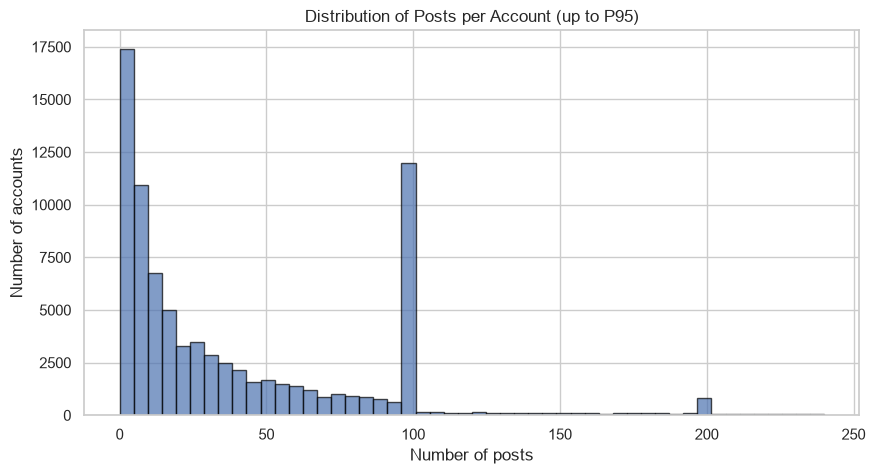

In [81]:
values = df_activity["post_count"]
upper_limit = values.quantile(0.95)

plt.figure(figsize=(10, 5))

plt.hist(
    values[values <= upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Posts per Account (up to P95)")
plt.xlabel("Number of posts")
plt.ylabel("Number of accounts")
plt.show()

There are 2 spikes at 100 and at 200 posts. This unusual concentration requires further
investigation.

In [82]:
display(
    df_activity["post_count"]
    .value_counts()
    .head(15)
    .rename("Number of accounts")
    .to_frame()
)

,Number of accounts
post_count,
99,11382
1,6026
2,4565
3,3733
4,3090
5,2761
6,2396
7,2123
8,1992


In [83]:
summary_99 = df_activity.groupby("ioCountry").agg(
    total_accounts=("post_count", "size"),
    accounts_with_99_posts=("post_count", lambda x: (x == 99).sum())
)

summary_99["percentage"] = (
    summary_99["accounts_with_99_posts"]
    / summary_99["total_accounts"] * 100
)

display(
    summary_99.sort_values("percentage", ascending=False).round(2)
)

,total_accounts,accounts_with_99_posts,percentage
ioCountry,,,
iran_1,5675,909,16.02
russia_1,34592,5058,14.62
ecuador,21924,2743,12.51
iran_4,10131,1254,12.38
uae,14203,1418,9.98


Accounts with exactly 99 posts appear across all five
information operations, with percentages ranging from
10.01% to 16.04%, so its not a result from a single country.

In [84]:
label_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=account_keys + ["is_control"],
    dtype="string",
    chunksize=CHUNK_SIZE
):
    label_chunks.append(chunk.drop_duplicates())

df_labels = pd.concat(label_chunks, ignore_index=True)
df_labels = df_labels.dropna().drop_duplicates()

# Exclude accounts with conflicting labels
df_labels = df_labels.drop_duplicates(
    subset=account_keys, keep=False
)

In [85]:
df_activity_labeled = df_activity.merge(
    df_labels,
    on=account_keys,
    how="left"
)

summary_99_class = df_activity_labeled.groupby("is_control").agg(
    total_accounts=("post_count", "size"),
    accounts_with_99_posts=("post_count", lambda x: (x == 99).sum())
)

summary_99_class["percentage"] = (
    summary_99_class["accounts_with_99_posts"]
    / summary_99_class["total_accounts"] * 100
)

display(summary_99_class.round(2))

,total_accounts,accounts_with_99_posts,percentage
is_control,,,
False,10916,20,0.18
True,75608,11362,15.03


Exactly 99 posts are observed in 15.24% of control accounts,
compared to only 0.18% of IO accounts, suggesting a potential
data collection artifact affecting control accounts.
lets check if there is a limit at 99

In [86]:
summary_posts = df_activity_labeled.groupby("is_control").agg(
    total_accounts=("post_count", "size"),
    below_99=("post_count", lambda x: (x < 99).sum()),
    exactly_99=("post_count", lambda x: (x == 99).sum()),
    above_99=("post_count", lambda x: (x > 99).sum()),
    max_posts=("post_count", "max")
)

display(summary_posts)

,total_accounts,below_99,exactly_99,above_99,max_posts
is_control,,,,,
False,10916,5738,20,5158,265448
True,75608,61647,11362,2599,19690


#### Conclusion

The unusual concentration at 99 posts may be related to
the data collection procedure rather than actual account
behavior. Its cause remains unconfirmed. But it can affect clustering,
we will its effect on clustering during feature selection

Now we will calculate the post intensity
### B.4 Posting Intensity

We combine post count and activity lifespan to measure
the average number of posts per day over each account's
observed activity period.

In [87]:
df_activity = df_activity.merge(
    df_temporal[account_keys + ["activity_lifespan_days"]],
    on=account_keys,
    how="left"
)

df_activity["posting_intensity"] = (
    df_activity["post_count"]
    / (df_activity["activity_lifespan_days"] + 1)
)

In [88]:
display(
    df_activity[["posting_intensity"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
posting_intensity,86525.0,29.05162,34.644893,0.0,3.0,11.571429,45.0,99.0,99.0,283.0


In [89]:
print("Accounts with posting intensity of 99:",
      (df_activity["posting_intensity"] == 99).sum())

print("Accounts with 99 posts and zero lifespan:",
      ((df_activity["post_count"] == 99) &
       (df_activity["activity_lifespan_days"] == 0)).sum())

Accounts with posting intensity of 99: 11397
Accounts with 99 posts and zero lifespan: 11356


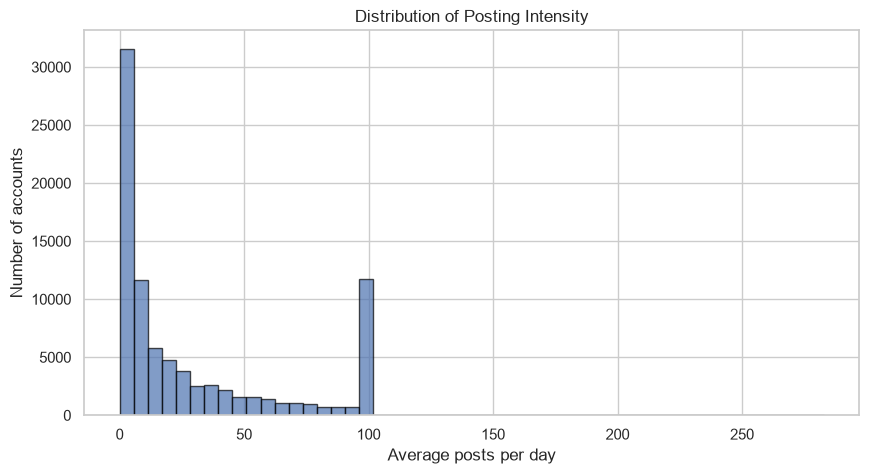

In [90]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_activity["posting_intensity"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Posting Intensity")
plt.xlabel("Average posts per day")
plt.ylabel("Number of accounts")

plt.show()

#### Observations

The posting intensity distribution is right-skewed,
with a noticeable concentration at 99 posts per day.

Therefore, posting intensity may also be affected by
the previously identified potential sampling bias.

### B.5 Interaction Behavior

We analyze reposts, replies and mentions to characterize
how accounts interact with other users and disseminate
information.

we will use rations to make the comparison fair between accounts (we want to study the behavior)


In [91]:

columns = account_keys + [
    "postid",
    "is_repost",
    "in_reply_to_postid",
    "in_reply_to_accountid",
    "account_mentions"
]

interaction_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Exclude records with ambiguous ownership
    chunk, _ = split_by_ownership(chunk)

    # Identify reposts
    repost_status = chunk["is_repost"].str.strip().str.lower()

    chunk["repost"] = repost_status.eq("true").fillna(False)
    chunk["known_repost"] = repost_status.isin(["true", "false"])

    # Identify replies
    chunk["reply"] = (
        chunk["in_reply_to_postid"].notna() |
        chunk["in_reply_to_accountid"].notna()
    )

    # Identify posts containing mentions
    mentions = chunk["account_mentions"].str.strip()

    chunk["known_mentions"] = (
        mentions.str.startswith("[", na=False) &
        mentions.str.endswith("]", na=False)
    )

    chunk["has_mention"] = (
        chunk["known_mentions"] &
        ~mentions.str.fullmatch(r"\[\s*\]", na=False)
    )

    # Aggregate information per account
    stats = chunk.groupby(account_keys).agg(
        post_count=("accountid", "size"),
        repost_count=("repost", "sum"),
        known_repost_count=("known_repost", "sum"),
        reply_count=("reply", "sum"),
        mention_count=("has_mention", "sum"),
        known_mention_count=("known_mentions", "sum")
    )

    interaction_chunks.append(stats)

df_interactions = (
    pd.concat(interaction_chunks)
    .groupby(level=[0, 1])
    .sum()
    .reset_index()
)

print("Interaction features calculated successfully.")
print("Accounts:", len(df_interactions))

display(df_interactions.head())


Interaction features calculated successfully.
Accounts: 86524


,ioCountry,accountid,post_count,repost_count,known_repost_count,reply_count,mention_count,known_mention_count
0,ecuador,0002e64fc6035627e87f8312ee9c8c0098b1d6cd2a,7,6,7,0,6,7
1,ecuador,0005c5f571ae94a562ab590fbcab9138cee6d20507,13,0,13,4,4,13
2,ecuador,0007a45e37da6ae559d6b4b76218874d6ab677234b,6,3,6,1,6,6
3,ecuador,000fca065490ad68fbb646d9491061b2abd861703f,24,2,24,16,19,24
4,ecuador,0011cb6aa969ab7bc4359a6c445287ca0671aac4c0,62,41,62,1,45,62


In [92]:
df_interactions["repost_ratio"] = (
    df_interactions["repost_count"]
    / df_interactions["known_repost_count"].replace(0, np.nan)
)

df_interactions["reply_ratio"] = (
    df_interactions["reply_count"]
    / df_interactions["post_count"]
)

df_interactions["mention_ratio"] = (
    df_interactions["mention_count"]
    / df_interactions["known_mention_count"].replace(0, np.nan)
)

In [93]:
interaction_features = [
    "repost_ratio",
    "reply_ratio",
    "mention_ratio"
]

display(
    df_interactions[interaction_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
repost_ratio,86524.0,0.440626,0.39854,0.0,0.0,0.363636,0.877551,1.0,1.0,1.0
reply_ratio,86524.0,0.109592,0.191015,0.0,0.0,0.0,0.142857,0.538462,0.833333,1.0
mention_ratio,86524.0,0.613197,0.385768,0.0,0.25,0.737374,1.0,1.0,1.0,1.0


Each bin represents a ratio interval of 0.05 (5%).

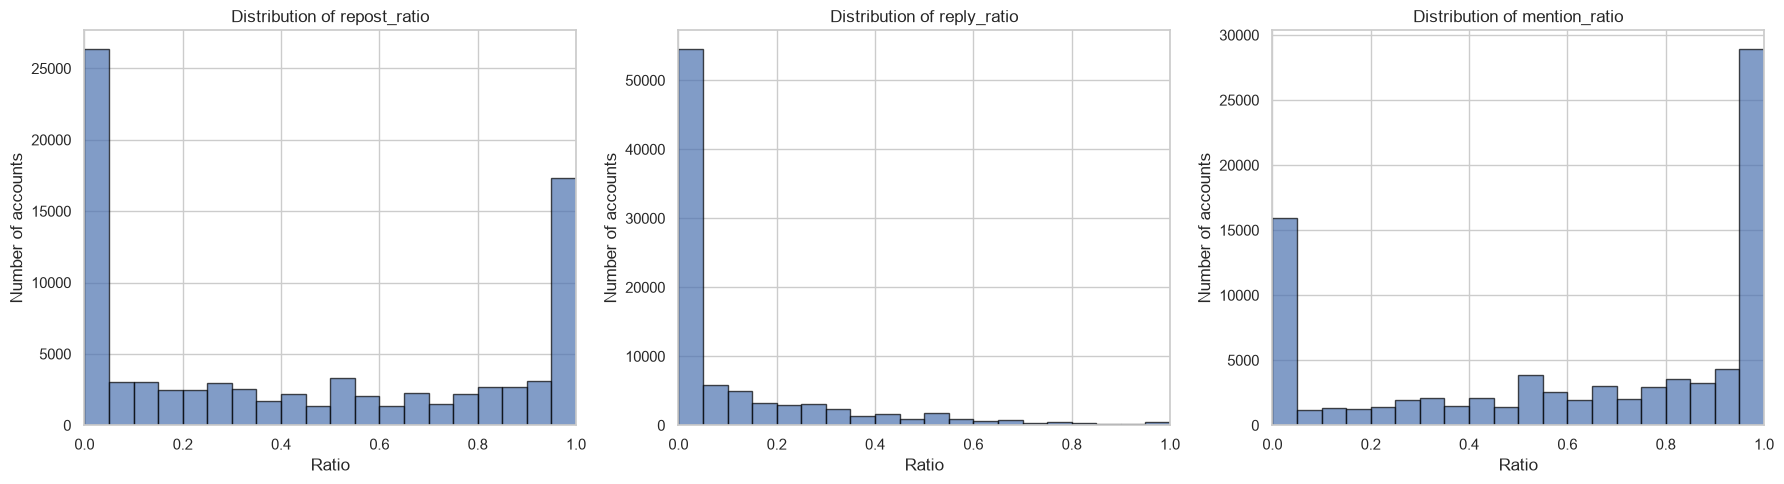

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, interaction_features):

    ax.hist(
        df_interactions[column].dropna(),
        bins=np.linspace(0, 1, 21),
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel("Ratio")
    ax.set_ylabel("Number of accounts")
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

reposts often contain mentions of the original author.
So potential redundancy between repost and mention ratios
will be investigated during correlation analysis.

Until now, we focused on how accounts behave. Next, we want to examine the characteristics of the content they publish.4
This can be useful for distinguishing behavioral patterns between IO and control accounts.

we will get things like do accounts use hashtags in posts, urls, etc, this can also help us in clustering

In [95]:
content_sample = pd.read_csv(
    DATA_PATH,
    usecols=["hashtags", "urls", "post_text"],
    dtype="string",
    nrows=10000
)

print("Hashtags:")
display(
    content_sample["hashtags"]
    .value_counts(dropna=False)
    .head(10)
)

print("URLs:")
display(
    content_sample["urls"]
    .value_counts(dropna=False)
    .head(10)
)

print("Post text examples:")
display(content_sample["post_text"].head(5))

Hashtags:


hashtags
[]                                                                                                                   7814
['LaCrudaVerdad']                                                                                                     202
['LCV']                                                                                                               124
['nowplaying']                                                                                                        111
['FF']                                                                                                                 73
['RT' 'FF' 'TeamFollowBack' '500ADAY' 'FollowAll' 'FollowFriday' 'Friday'\n 'autofollow' 'FollowBack' 'FollowMe']      35
['lacrudaverdad']                                                                                                      32
['FF' 'TeamFollowBack' 'FollowAll' 'autofollow' 'FollowBack' 'FollowMe']                                               32
['VzlaOffRoad']

URLs:


urls
[]                                                        9216
['https://20cf09697662227e7f7635f02e4c3663e52999e877']      61
['https://46926622555b6e7d8b3db9eceefc18560aee799169']      21
['https://64bd920098f09dd6b78acdae516e9f398d0b86ef19']      13
['https://01af12ee6e9b4b728ae4b6fe07fe80977095692160']       9
['https://e79bd02d6df9c731de356df4d03ef11a3ad60694ae']       6
['https://48d372bac2ae1efa2805f0b624bc83077e50e48796']       5
['https://d3865712d27f07cac336e5c489e3434d1bb08430ab']       4
['https://51453886766b1616f04cbc7a3ca084703dccc56c11']       4
['https://5929a59f2dc4a5bd3ae966cbce9a6f2ab0cb4c31a7']       3
Name: count, dtype: Int64

Post text examples:


0    Vamos a cambiar la forma de hacer comunicación...
1    Damos servicio de manejo de prensa, elaboració...
2    @db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...
3    Mario, debemos denuciar que en los poderes pub...
4    Tambien debemos estar claro que la oposición e...
Name: post_text, dtype: string

In [96]:
columns = account_keys + [
    "postid",
    "hashtags",
    "urls",
    "post_text"
]

content_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Exclude ambiguous ownership records
    chunk, _ = split_by_ownership(chunk)
    # Hashtags
    hashtags = chunk["hashtags"].str.strip()

    chunk["known_hashtags"] = (
        hashtags.str.startswith("[", na=False) &
        hashtags.str.endswith("]", na=False)
    )

    chunk["has_hashtag"] = (
        chunk["known_hashtags"] &
        ~hashtags.str.fullmatch(r"\[\s*\]", na=False)
    )

    # URLs
    urls = chunk["urls"].str.strip()

    chunk["known_urls"] = (
        urls.str.startswith("[", na=False) &
        urls.str.endswith("]", na=False)
    )

    chunk["has_url"] = (
        chunk["known_urls"] &
        ~urls.str.fullmatch(r"\[\s*\]", na=False)
    )

    # Post length
    chunk["post_length"] = chunk["post_text"].str.len()
    chunk["known_text"] = chunk["post_text"].notna()

    # Aggregate per account
    stats = chunk.groupby(account_keys).agg(
        hashtag_posts=("has_hashtag", "sum"),
        known_hashtag_posts=("known_hashtags", "sum"),
        url_posts=("has_url", "sum"),
        known_url_posts=("known_urls", "sum"),
        total_post_length=("post_length", "sum"),
        known_text_posts=("known_text", "sum")
    )

    content_chunks.append(stats)

df_content = (
    pd.concat(content_chunks)
    .groupby(level=[0, 1])
    .sum()
    .reset_index()
)

# Calculate account-level features
df_content["hashtag_ratio"] = (
    df_content["hashtag_posts"]
    / df_content["known_hashtag_posts"].replace(0, np.nan)
)

df_content["url_ratio"] = (
    df_content["url_posts"]
    / df_content["known_url_posts"].replace(0, np.nan)
)

df_content["avg_post_length"] = (
    df_content["total_post_length"]
    / df_content["known_text_posts"].replace(0, np.nan)
)

In [97]:
content_features = [
    "hashtag_ratio",
    "url_ratio",
    "avg_post_length"
]

display(
    df_content[content_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
hashtag_ratio,86524.0,0.555478,0.321534,0.0,0.277778,0.5,0.889764,1.0,1.0,1.0
url_ratio,86524.0,0.551131,0.359303,0.0,0.222222,0.571429,0.928571,1.0,1.0,1.0
avg_post_length,86524.0,140.199514,65.710024,2.0,99.781566,132.333333,165.25,249.410417,332.5,2054.020202


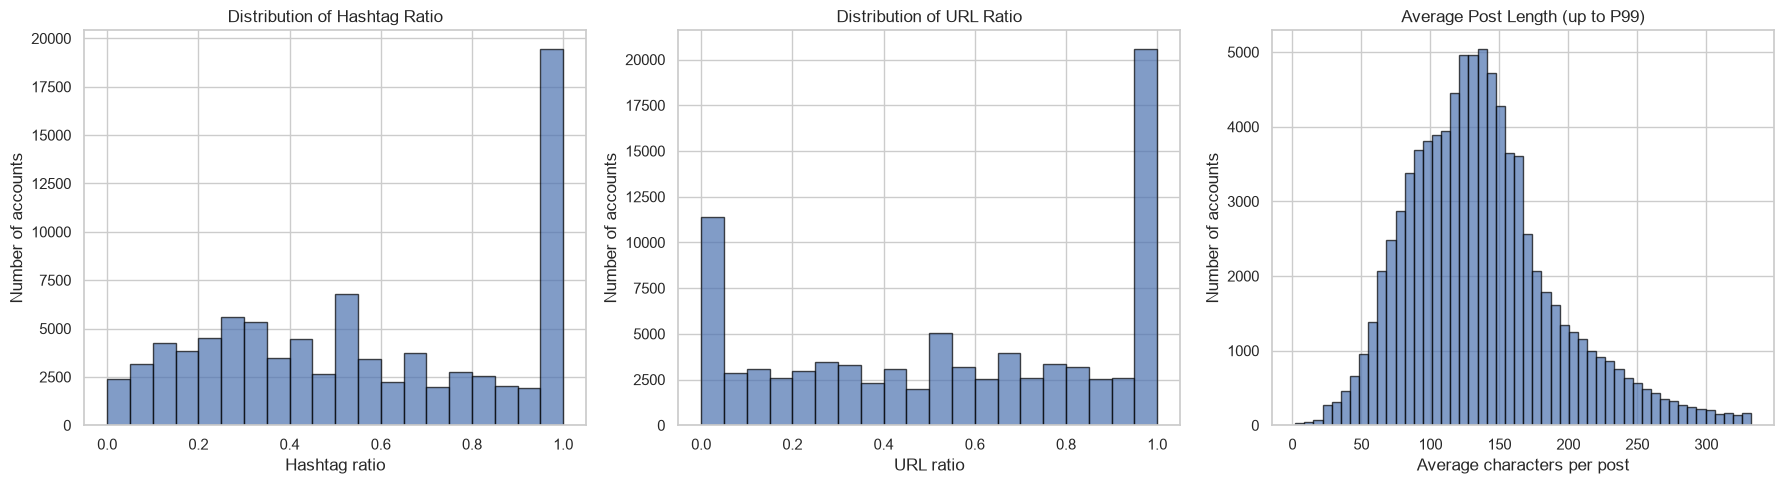

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Hashtag ratio
axes[0].hist(
    df_content["hashtag_ratio"].dropna(),
    bins=np.linspace(0, 1, 21),
    edgecolor="black",
    alpha=0.7
)
axes[0].set_title("Distribution of Hashtag Ratio")
axes[0].set_xlabel("Hashtag ratio")
axes[0].set_ylabel("Number of accounts")

# URL ratio
axes[1].hist(
    df_content["url_ratio"].dropna(),
    bins=np.linspace(0, 1, 21),
    edgecolor="black",
    alpha=0.7
)
axes[1].set_title("Distribution of URL Ratio")
axes[1].set_xlabel("URL ratio")
axes[1].set_ylabel("Number of accounts")

# Average post length
values = df_content["avg_post_length"].dropna()
upper_limit = values.quantile(0.99)

axes[2].hist(
    values[values <= upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.7
)
axes[2].set_title("Average Post Length (up to P99)")
axes[2].set_xlabel("Average characters per post")
axes[2].set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

### Language and Application Usage

We analyze the number of distinct languages and publishing
applications used by each account to investigate diversity
in communication and posting behavior.

In [99]:

columns = account_keys + [
    "postid",
    "post_language",
    "application_name"
]

language_chunks = []
application_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Exclude records with ambiguous post ownership
    chunk, _ = split_by_ownership(chunk)

    # Remove records with missing account identifiers
    chunk = chunk.dropna(subset=account_keys)

    # Exclude missing or unspecified language labels
    languages = chunk.dropna(subset=["post_language"]).copy()
    languages["post_language"] = languages["post_language"].str.strip()

    languages = languages[
        ~languages["post_language"].str.lower().isin(
            ["", "und", "unknown"]
        )
    ]

    language_chunks.append(
        languages[
            account_keys + ["post_language"]
        ].drop_duplicates()
    )

    # Identify distinct publishing applications
    applications = chunk.dropna(
        subset=["application_name"]
    ).copy()

    applications["application_name"] = (
        applications["application_name"].str.strip()
    )

    applications = applications[
        applications["application_name"] != ""
    ]

    application_chunks.append(
        applications[
            account_keys + ["application_name"]
        ].drop_duplicates()
    )

# Remove duplicates across different chunks
unique_language_pairs = (
    pd.concat(
        language_chunks,
        ignore_index=True
    ).drop_duplicates()
)

unique_application_pairs = (
    pd.concat(
        application_chunks,
        ignore_index=True
    ).drop_duplicates()
)

# Count unique values for every account
language_counts = (
    unique_language_pairs.groupby(account_keys)
    .size()
    .rename("unique_languages")
    .reset_index()
)

application_counts = (
    unique_application_pairs.groupby(account_keys)
    .size()
    .rename("unique_applications")
    .reset_index()
)

# Merge account diversity features
df_diversity = (
    df_activity[account_keys].drop_duplicates()
    .merge(
        language_counts,
        on=account_keys,
        how="left"
    )
    .merge(
        application_counts,
        on=account_keys,
        how="left"
    )
)

# Replace missing diversity counts with zero
df_diversity[
    ["unique_languages", "unique_applications"]
] = (
    df_diversity[
        ["unique_languages", "unique_applications"]
    ]
    .fillna(0)
    .astype(int)
)

print("Language and application diversity calculated.")
print("Total accounts:", len(df_diversity))

display(df_diversity.head())


Language and application diversity calculated.
Total accounts: 86525


,ioCountry,accountid,unique_languages,unique_applications
0,iran_1,3078c8b2dc886ae19d8d044c4100112957f0a09fbe,1,1
1,ecuador,28ec9544126e65f95cc391f3af31e1d2b580eedb51,3,2
2,uae,a7b3219804c32d6ee9588db26a7d1b33c88fded415,2,1
3,russia_1,3c63ffc55de4f9b74d3e6cf59e68f3d3edef63cfe3,7,1
4,iran_4,58cfe279365edaa72346fddc445ad16b0c4db289f4,1,1


In [100]:
diversity_features = [
    "unique_languages",
    "unique_applications"
]

display(
    df_diversity[diversity_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
unique_languages,86525.0,2.240081,2.360567,0.0,1.0,1.0,3.0,6.0,12.0,40.0
unique_applications,86525.0,1.652228,1.377820,0.0,1.0,1.0,2.0,4.0,7.0,69.0


In [101]:
for column in diversity_features:
    print(f"\n{column}")
    print(
        df_diversity[column]
        .value_counts()
        .sort_index()
        .head(15)
    )


unique_languages
unique_languages
0       872
1     44896
2     18608
3      8802
4      4709
5      2757
6      1898
7      1090
8       714
9       511
10      424
11      235
12      199
13      148
14      102
Name: count, dtype: int64

unique_applications
unique_applications
0         1
1     55296
2     19400
3      6937
4      2501
5       955
6       371
7       241
8       162
9        95
10      100
11      100
12      109
13       92
14       62
Name: count, dtype: int64


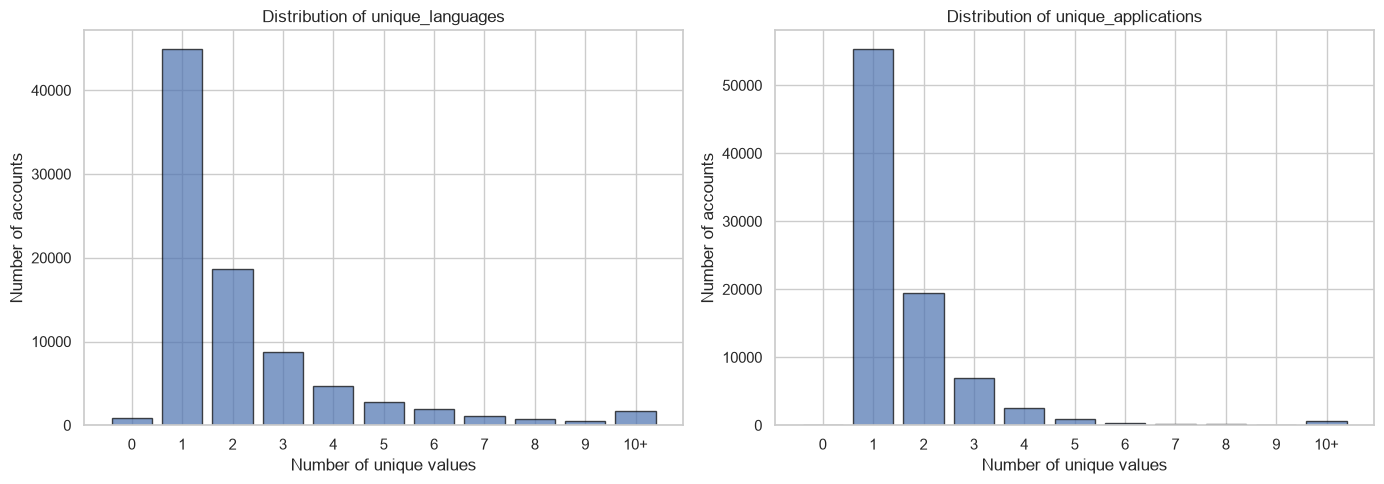

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, diversity_features):

    values = df_diversity[column]

    # Group larger values to simplify visualization
    grouped = values.clip(upper=10)
    counts = grouped.value_counts().sort_index()

    ax.bar(counts.index, counts.values, edgecolor="black", alpha=0.7)

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel("Number of unique values")
    ax.set_ylabel("Number of accounts")
    ax.set_xticks(range(11))
    ax.set_xticklabels([str(i) for i in range(10)] + ["10+"])

plt.tight_layout()
plt.show()

#### Observations

Most accounts use only one identified language (51.9%)
and one publishing application (63.9%).

A smaller proportion uses multiple languages or applications,
indicating different levels of diversity.

These features may be useful for clustering, also, their
relationship with posting volume should be considered(more posts -> more opportunities to use different languages).

## C. Correlation Analysis

We investigate relationships between numerical account-level
features to identify potential redundancy.

Spearman correlation is used because several features have
skewed distributions and extreme values.

During the previous analysis, we extracted original account attributes and created new behavioral features, such as posting intensity, interaction ratios, and content characteristics.

We now combine these features into a single account-level dataframe.

In [103]:

# ============================================================
# C.1 ACCOUNT-LEVEL FEATURE INTEGRATION AND VALIDATION
# ============================================================

# 1. Create the account-level dataset
# Include reliable post counts and ambiguous ownership counts

df_eda = df_activity[
    account_keys + [
        "post_count",
        "ambiguous_post_count",
        "posting_intensity"
    ]
].copy()


# 2. Merge features calculated in previous sections

feature_tables = [
    df_accounts[
        account_keys + ["follower_count", "following_count"]
    ],
    df_temporal[
        account_keys + ["account_age_days", "activity_lifespan_days"]
    ],
    df_interactions[
        account_keys + ["repost_ratio", "reply_ratio", "mention_ratio"]
    ],
    df_content[
        account_keys + ["hashtag_ratio", "url_ratio", "avg_post_length"]
    ],
    df_diversity[
        account_keys + ["unique_languages", "unique_applications"]
    ]
]

for table in feature_tables:
    df_eda = df_eda.merge(
        table,
        on=account_keys,
        how="left",
        validate="one_to_one"
    )


# 3. Validate account-level aggregation

print("=== ACCOUNT AGGREGATION VALIDATION ===")

# Verify ownership filtering results
assert df_activity["ambiguous_post_count"].sum() == 460, (
    "Unexpected number of ambiguous ownership records."
)

assert df_activity["post_count"].sum() == 8_712_317, (
    "Unexpected number of reliable posts."
)

# Verify that all accounts are preserved
assert len(df_eda) == len(df_activity), (
    "Some accounts were lost or duplicated during merging."
)

# Verify each country-account combination is unique
assert not df_eda.duplicated(
    subset=account_keys
).any(), (
    "Duplicate country-account combinations detected."
)

# Verify post counts are consistent
assert (
    df_eda["post_count"].sum()
    + df_eda["ambiguous_post_count"].sum()
    == 8_712_777
), "Account-level counts do not match the cleaned dataset."

print("Account aggregation validation: PASSED")


# 4. Display final account-level dataset summary

print("\n=== FINAL ACCOUNT-LEVEL DATASET ===")

print(f"Number of account profiles: {len(df_eda):,}")
print(f"Number of attributes: {len(df_eda.columns)}")

print(f"Reliable posts: {df_eda['post_count'].sum():,}")
print(
    f"Ambiguous ownership records: "
    f"{df_eda['ambiguous_post_count'].sum():,}"
)

# 5. Display all attributes

print("\n=== ATTRIBUTES ===")

for index, column in enumerate(df_eda.columns, start=1):
    print(f"{index:02d}. {column}")


# 6. Preview account-level profiles

print("\n=== FIRST FIVE ACCOUNT PROFILES ===")
display(df_eda.head())


=== ACCOUNT AGGREGATION VALIDATION ===
Account aggregation validation: PASSED

=== FINAL ACCOUNT-LEVEL DATASET ===
Number of account profiles: 86,525
Number of attributes: 17
Reliable posts: 8,712,317
Ambiguous ownership records: 460

=== ATTRIBUTES ===
01. ioCountry
02. accountid
03. post_count
04. ambiguous_post_count
05. posting_intensity
06. follower_count
07. following_count
08. account_age_days
09. activity_lifespan_days
10. repost_ratio
11. reply_ratio
12. mention_ratio
13. hashtag_ratio
14. url_ratio
15. avg_post_length
16. unique_languages
17. unique_applications

=== FIRST FIVE ACCOUNT PROFILES ===


,ioCountry,accountid,post_count,ambiguous_post_count,posting_intensity,follower_count,following_count,account_age_days,activity_lifespan_days,repost_ratio,reply_ratio,mention_ratio,hashtag_ratio,url_ratio,avg_post_length,unique_languages,unique_applications
0,iran_1,3078c8b2dc886ae19d8d044c4100112957f0a09fbe,13,0,13.000000,13396.0,231.0,1515,0,0.384615,0.153846,0.846154,0.538462,0.615385,169.846154,1,1
1,ecuador,28ec9544126e65f95cc391f3af31e1d2b580eedb51,23,0,23.000000,906.0,464.0,1285,0,0.391304,0.043478,0.434783,0.086957,0.217391,59.478261,3,2
2,uae,a7b3219804c32d6ee9588db26a7d1b33c88fded415,35,0,2.916667,7.0,29.0,24,11,0.285714,0.142857,0.457143,0.142857,0.114286,72.285714,2,1
3,russia_1,3c63ffc55de4f9b74d3e6cf59e68f3d3edef63cfe3,99,0,99.000000,333.0,254.0,76,0,0.0,0.000000,0.0,0.393939,0.0,25.858586,7,1
4,iran_4,58cfe279365edaa72346fddc445ad16b0c4db289f4,1,0,1.000000,4148.0,4442.0,1278,0,0.0,0.000000,0.0,1.0,1.0,131.0,1,1


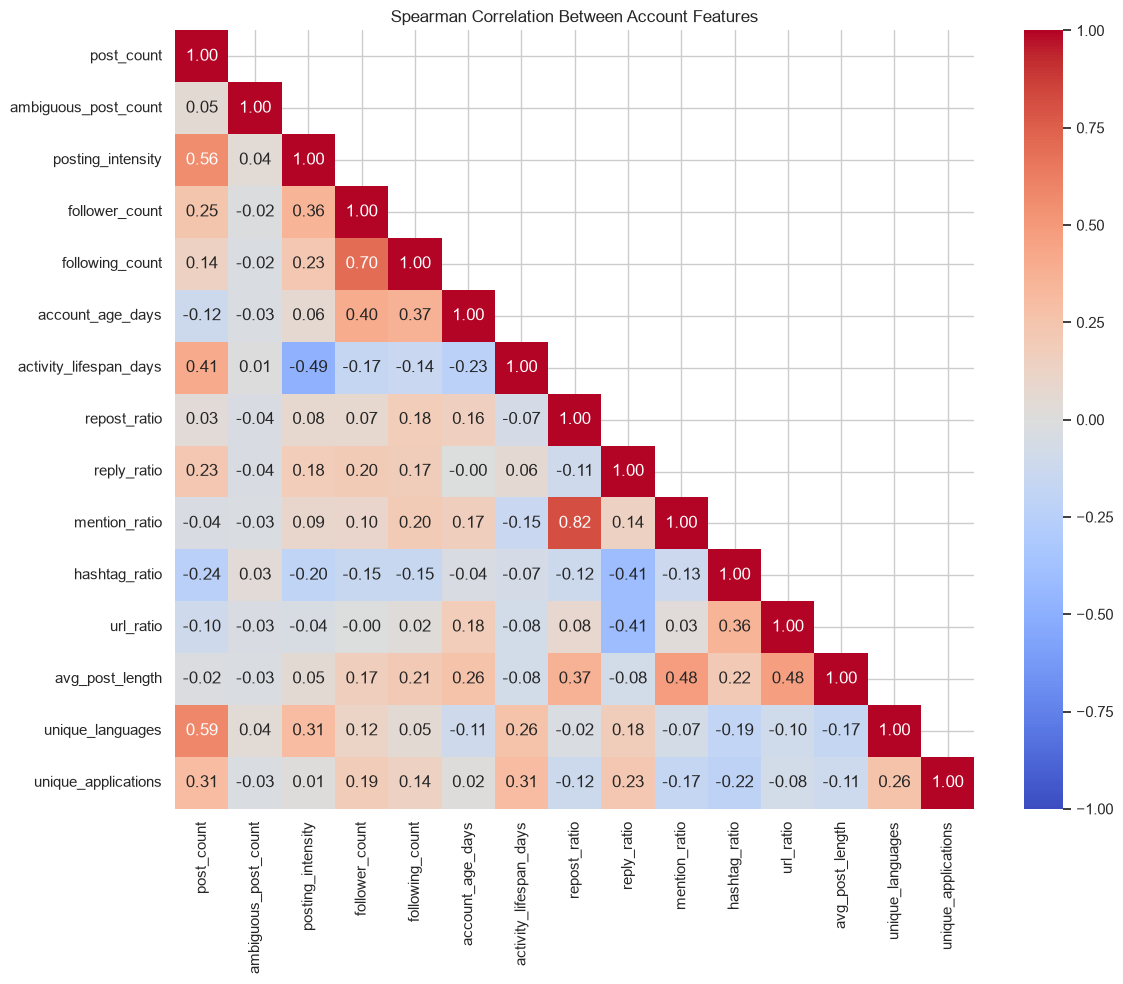

In [104]:
# Calculate Spearman correlation
correlation_matrix = df_eda.drop(columns=account_keys).corr(method="spearman")

# Hide the upper triangle (duplicate correlations)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Spearman Correlation Between Account Features")
plt.tight_layout()
plt.show()

#### Correlation Analysis — Observations

- A strong positive correlation (+0.82) exists between
  repost_ratio and mention_ratio, suggesting potential redundancy.
- Follower and following counts are positively correlated (+0.70).
- Post count and unique languages are moderately correlated (+0.59),
  possibly reflecting differences in observed posting volume.
- Posting intensity and activity lifespan are negatively correlated
  (-0.49), partly due to how posting intensity is calculated.
- Highly correlated features will be reconsidered during
  feature selection to avoid unnecessary redundancy in clustering.

Until now, we analyzed all accounts together. We will now compare Information Operations (IO) accounts with control accounts to understand how their behavior differs.

In [105]:
# Add the account labels to our account-level dataset
df_comparison = df_eda.merge(
    df_labels[account_keys + ["is_control"]],
    on=account_keys,
    how="left",
    validate="one_to_one"
)

# Create readable group names
df_comparison["account_group"] = (
    df_comparison["is_control"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"false": "IO", "true": "Control"})
)

print("Total account profiles:", len(df_comparison))

print("\nAccounts by group:")
print(df_comparison["account_group"].fillna("Unknown").value_counts())

print("\nAccounts by operation and group:")
display(
    pd.crosstab(
        df_comparison["ioCountry"],
        df_comparison["account_group"].fillna("Unknown")
    )
)

Total account profiles: 86525

Accounts by group:
account_group
Control    75608
IO         10916
Unknown        1
Name: count, dtype: int64

Accounts by operation and group:


account_group,Control,IO,Unknown
ioCountry,,,
ecuador,21137,786,1
iran_1,5015,660,0
iran_4,7612,2519,0
russia_1,31299,3293,0
uae,10545,3658,0


In [106]:
# Main behavioral features to compare
behavior_features = [
    "post_count",
    "posting_intensity",
    "repost_ratio",
    "reply_ratio",
    "mention_ratio",
    "hashtag_ratio",
    "url_ratio",
    "avg_post_length"
]

# Exclude the one account with an unresolved label
df_valid = df_comparison[
    df_comparison["account_group"].isin(["IO", "Control"])
]

# Calculate median feature values for both groups
group_medians = (
    df_valid
    .groupby("account_group")[behavior_features]
    .median()
    .T
)

# Add the difference between IO and Control
group_medians["Difference (IO - Control)"] = (
    group_medians["IO"] - group_medians["Control"]
)

display(group_medians.round(3))

account_group,Control,IO,Difference (IO - Control)
post_count,20.0,88.0,68.0
posting_intensity,16.0,1.068496,-14.931504
repost_ratio,0.380952,0.306047,-0.074905
reply_ratio,0.0,0.023166,0.023166
mention_ratio,0.777778,0.508569,-0.269209
hashtag_ratio,0.518519,0.4,-0.118519
url_ratio,0.625,0.358737,-0.266263
avg_post_length,135.818182,118.689705,-17.128477


These results suggest that IO and control accounts exhibit different posting, interaction, and content behaviors. Such differences may help us identify useful features for clustering.

### D.3 — Distribution Comparison

We compare the distributions of selected features between IO and control accounts to better understand their differences and determine how much the groups overlap.

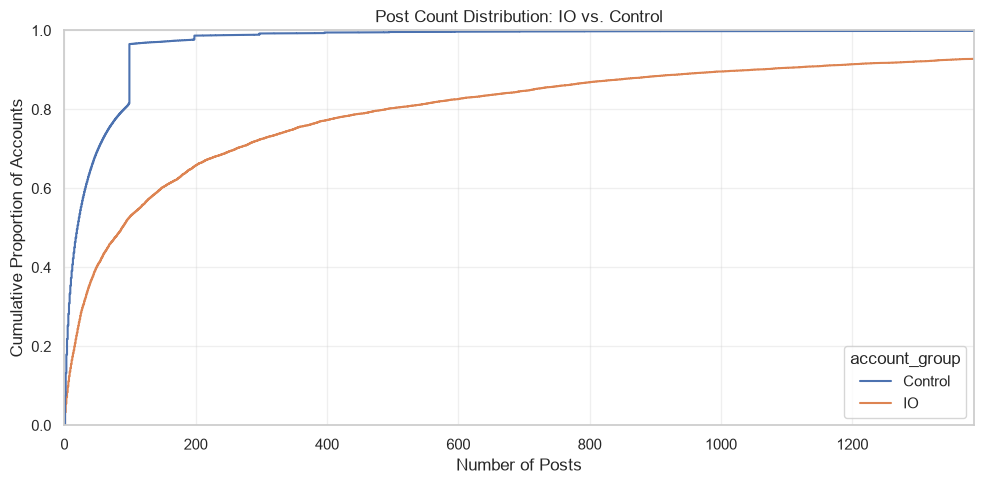

In [107]:
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df_valid,
    x="post_count",
    hue="account_group",
    hue_order=["Control", "IO"]
)

# Focus on the first 99% of observed post counts
plt.xlim(0, df_valid["post_count"].quantile(0.99))

plt.title("Post Count Distribution: IO vs. Control")
plt.xlabel("Number of Posts")
plt.ylabel("Cumulative Proportion of Accounts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

IO accounts generally have higher observed post counts than control accounts.

However, notice the sharp increase in the blue curve around 99 posts. This relates to the unusual concentration of control accounts with exactly 99 posts that we identified earlier.

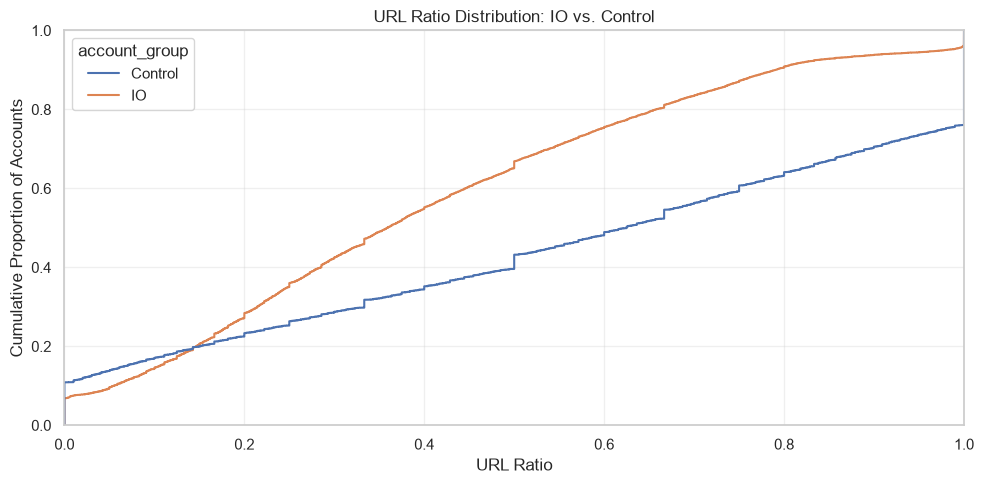

In [108]:
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df_valid,
    x="url_ratio",
    hue="account_group",
    hue_order=["Control", "IO"]
)

plt.xlim(0, 1)
plt.title("URL Ratio Distribution: IO vs. Control")
plt.xlabel("URL Ratio")
plt.ylabel("Cumulative Proportion of Accounts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### URL Ratio Distribution — Observations

- Control accounts generally have higher URL ratios than IO accounts.
- Both groups show overlapping distributions.
- URL ratio may be a useful feature for clustering, but it cannot distinguish the groups on its own.

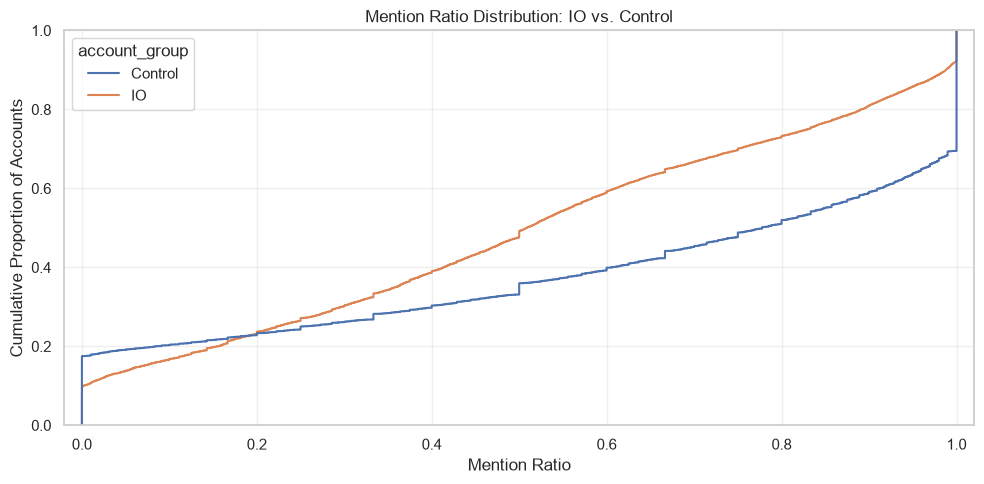

In [109]:
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df_valid,
    x="mention_ratio",
    hue="account_group",
    hue_order=["Control", "IO"]
)

plt.xlim(-0.02, 1.02)
plt.title("Mention Ratio Distribution: IO vs. Control")
plt.xlabel("Mention Ratio")
plt.ylabel("Cumulative Proportion of Accounts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Mention Ratio Distribution — Observations

- Control accounts generally have higher mention ratios than IO accounts.
- A substantial proportion of control accounts have a mention ratio of 1.
- Both groups have overlapping distributions, so mention ratio alone cannot reliably distinguish them.
- Mention and repost ratios are strongly correlated, suggesting potentially redundant information.

In [110]:
# Save account-level features for the next stage
ACCOUNT_FEATURES_PATH = DATA_PATH.parent / "df_account_features_eda.csv.gz"

df_eda.to_csv(
    ACCOUNT_FEATURES_PATH,
    index=False,
    compression="gzip"
)

print("Dataset saved to:", ACCOUNT_FEATURES_PATH)
print("Account profiles:", len(df_eda))
print("Numerical features:", len(df_eda.columns) - len(account_keys))

Dataset saved to: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-/data/data_processed/df_account_features_eda.csv.gz
Account profiles: 86525
Numerical features: 15


### E. Saving Account Labels for Clustering Evaluation

We save the original IO/control labels separately from the account-level features.

These labels will not be used during unsupervised clustering, but will be used afterward to evaluate the resulting clusters.

In [111]:
# Save account labels for external clustering evaluation
LABELS_PATH = DATA_PATH.parent / "df_account_labels.csv.gz"

df_labels[
    account_keys + ["is_control"]
].to_csv(
    LABELS_PATH,
    index=False,
    compression="gzip"
)

print("Labels saved to:", LABELS_PATH)
print("Account labels:", len(df_labels))
print(
    "Duplicate account keys:",
    df_labels.duplicated(subset=account_keys).sum()
)

Labels saved to: /Users/ramy/Courses/Data Mining /project/Data-Mining-Project-/data/data_processed/df_account_labels.csv.gz
Account labels: 86524
Duplicate account keys: 0
